# Phase 4a: Just SFT — Direct Arithmetic (`arith_v2`)

Evaluates **direct-answer Phase 4 Arithmetic SFT** (`What is 28 + 53?\nAnswer:` -> `81<|eos|>`, without Chain-of-Thought scratchpads), such as run `ef3cc27c...` (`8,000` steps, `89.6%` peak on `240` `val` rows).

- **Data Prep CLI:** `bash scripts/prepare_data.sh`
- **Training CLI:** `bash scripts/train.sh sft --preset sft --steps 8000 --eval-every 500`

In [1]:
from pathlib import Path
import sys

root = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "main.py").is_file()), Path.cwd().parent)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.infra.eval_setup import setup_notebook_environment, configure_eval_device

project_root = setup_notebook_environment(root)
device, dtype = configure_eval_device("auto")  # 'auto', 'cuda', or 'cpu'

c:\Users\sampa\Dev\MiniReasoner\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root located at: C:\Users\sampa\Dev\MiniReasoner
ACTIVE EXECUTION DEVICE: CPU
CPU Threads:        4
Inference Dtype:    torch.float32
Mode:               Portable CPU Inference


## 1. Load Direct SFT Checkpoint (`arith_format='direct'`)

Discovered 8 run(s) in Azure container 'minireasoner':

Run ID                              Stage     Format      MLflow State  Snapshots  Last Updated (UTC)
--------------------------------------------------------------------------------------------------------
ef3cc27cede44edf90ff5f205a2f71d6    sft       direct      active        16         2026-11-25 17:43:41
e8996fa3b67f48c8951cfd20f68ab40b    sft       direct      active        6          2026-11-25 17:17:13
e57bf52bb95842dba6628092261584c4    sft       scratchpad  active        20         2026-11-26 05:56:23
23a72f3aa8d6487ca401b92b22ae229c    pretrain  -           active        53         2026-11-24 19:09:03
655ddf770790468d988bbb0375fd5aa4    pretrain  -           active        48         2026-11-24 09:22:26
f9a6d03c46af4a378895622a82ace4c3    sft       direct      deleted       6          2026-11-25 17:12:04
6ef108a339da46679718b67143c39e2e    sft       scratchpad  deleted       4          2026-11-26 05:15:53
c26cf6e5ffc749e6

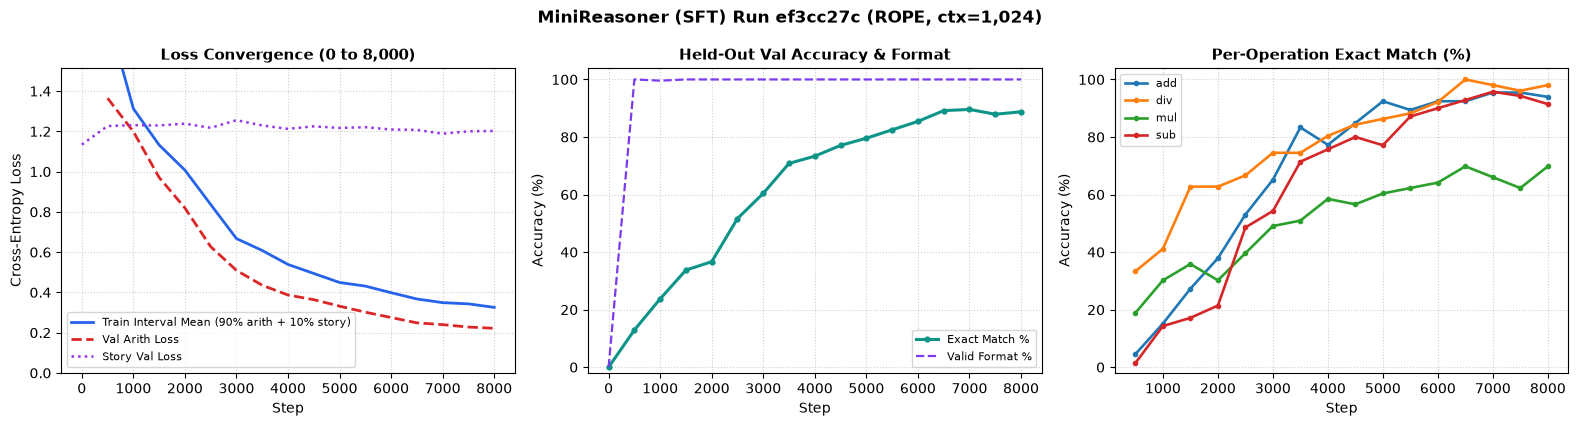

Initial Val Loss:        8.8161 (Step 0)
Latest Logged Val Loss:  0.2217 (Step 8,000)
Best Val Loss:           0.2217 (Step 8,000)
Peak Val Exact Match:    89.6% (Step 7,000)
Final Val Exact Match:   88.8% (Step 8,000)
Story Val Loss:          1.1341 (Step 0) -> 1.2021 (Step 8,000)


In [2]:
from src.infra.eval_setup import select_run_and_checkpoint, load_checkpoint_bundle, plot_run_history

RUN_ID = None                # Auto-selects newest active Direct SFT run (e.g. ef3cc27c...)
CHECKPOINT_ALIAS = "latest"  # 'latest' (8k), 'best', or 'step-N'
LOCAL_CHECKPOINT = None
COMPARE_WITH_BASE = False    # Set True to also load parent Base checkpoint for side-by-side comparison

run_id, ckpt_path, snapshot = select_run_and_checkpoint(
    run_id=RUN_ID,
    checkpoint_alias=CHECKPOINT_ALIAS,
    local_checkpoint=LOCAL_CHECKPOINT,
    preferred_stages=("sft",),
    preferred_arith_format="direct",
)
bundle = load_checkpoint_bundle(ckpt_path, device, dtype, snapshot=snapshot, compare_with_base=COMPARE_WITH_BASE)
model, tokenizer, model_config = bundle["model"], bundle["tokenizer"], bundle["model_config"]
arith_manifest = bundle["arith_manifest"]
plot_run_history(bundle["metrics_history"], run_id=run_id, model_config=model_config, stage=bundle["stage"], snapshot=snapshot)

## 2. Evaluate Direct SFT on Held-Out `val` Split (Standard Direct Format)

In [3]:
from src.core.benchmark import evaluate_arithmetic_split

EVAL_SPLIT = "val"                                       # Keep 'val' until Phase 6
MAX_EXAMPLES = 240 if device.type == "cpu" else None     # Set None to run all 4,802 val rows

eval_res = evaluate_arithmetic_split(
    model,
    tokenizer,
    model_config,
    arith_manifest,
    device=device,
    dtype=dtype,
    eval_split=EVAL_SPLIT,
    max_examples=MAX_EXAMPLES,
    batch_size=32,
    use_kv_cache=False,
    base_model=bundle["base_model"],
    base_tokenizer=bundle["base_tokenizer"],
)

PHASE 4 ARITHMETIC EVALUATION | split=val (240 rows) | format=direct | multistep=False | kv_cache=False
Dataset:  C:\Users\sampa\Dev\MiniReasoner\data\sft\arithmetic\arith_v2_add-sub-mul-div_d3_signed_n12000_s42
Hardware: CPU | batch_size=32 | max_new_tokens=32
Computed masked val arith loss: 0.1318 (879 targets in 6.2s)
  Decoded 200/240 (83.3%) | 24.1s | 8.3 ex/s | ETA 4.8s
  Decoded 240/240 (100.0%) | 29.7s | 8.1 ex/s | ETA 0.0s

OVERALL VAL RESULTS (240 problems in 29.7s | 8.1 ex/s)
Exact Match Accuracy: 213/240 (88.75%)
Valid Format Rate:    240/240 (100.00%)
Masked Arith Loss:    0.1318

Per-Operation Breakdown:
  Op        Correct     Total     Accuracy
  ------------------------------------------
  add       59          63        93.65%
  div       49          50        98.00%
  mul       37          53        69.81%
  sub       68          74        91.89%

Per-Category Breakdown:
  Category                Correct   Total     Accuracy
  ----------------------------------------

## 3. Wording Generalization & SimpleStories Retention

In [4]:
from src.core.benchmark import evaluate_wording_generalization, generate_timed

evaluate_wording_generalization(
    model,
    tokenizer,
    eval_res["examples"],
    device=device,
    answer_format="direct",
    n_problems=12 if device.type == "cuda" else 6,
    max_new_tokens=eval_res["max_new_tokens"],
    use_kv_cache=False,
)

print("\nSimpleStories Retention Sanity Check:")
for sp in ("Once upon a time, there was a little", "Mia had a little dog named"):
    res = generate_timed(model, tokenizer, sp, max_new_tokens=60, temperature=0.0, use_cache=False, device=device)
    print(f"  {res['full_text'].strip()}")

WORDING GENERALIZATION (6 held-out problems, format=direct)
  calculate                6/6   (100.0%)
  canonical                6/6   (100.0%)
  equation                 6/6   (100.0%)
  word_numbers             6/6   (100.0%)
  word_op                  6/6   (100.0%)

SimpleStories Retention Sanity Check:
  Once upon a time, there was a little girl named Mia who loved to play. She would run around the yard, laughing and shouting. One day, she found a shiny stone. It sparkled like stars. Mia picked it up and felt a warm glow. She thought it was special.
  Mia had a little dog named Leo. He was barking loudly, and Mia felt a little scared. "What is wrong?" she asked. Leo looked up and said, "I lost my ball! It was a ball!" Mia wanted to help. "Let's find it together!"


## 4. Direct SFT Prompt Playground

In [5]:
from src.core.benchmark import create_ask_helper, create_math_chat_helpers

ask_math, _ = create_math_chat_helpers(model, tokenizer, device=device, answer_format="direct", use_cache=False)
ask = create_ask_helper(model, tokenizer, device=device, answer_format="direct", use_cache=False)

for q, gold in [("What is 28 + 53?", 81), ("What is -144 / 12?", -12), ("What is 6 * 45?", 270), ("What is 177 * 515?", 91155)]:
    ask_math(q, expected=gold)

Q: What is 28 + 53? [PASS]
   81
   -> Extracted: 81 (2 tok | 208ms | 9.6 tok/s)
------------------------------------------------------------------------------
Q: What is -144 / 12? [MISS | expected -12]
   -9
   -> Extracted: -9 (2 tok | 133ms | 15.0 tok/s)
------------------------------------------------------------------------------
Q: What is 6 * 45? [MISS | expected 270]
   260
   -> Extracted: 260 (3 tok | 158ms | 19.0 tok/s)
------------------------------------------------------------------------------
Q: What is 177 * 515? [MISS | expected 91155]
   94995
   -> Extracted: 94995 (5 tok | 197ms | 25.4 tok/s)
------------------------------------------------------------------------------


In [17]:
ask("He is chilling", verbose=False)

{'mode': 'story',
 'question': 'He is chilling',
 'completion': ' and accepting the moment.\n\nWith each passing minute, he felt the weight of his sorrow. He wanted to shout, to scream, to tell them he was not a fool. But the words felt heavy on his tongue. The boy who had fallen for the truth was nowhere to be found. The philosopher realized that the choice to be honest had only brought more pain. \n\nFinally, he',
 'full_text': 'He is chilling and accepting the moment.\n\nWith each passing minute, he felt the weight of his sorrow. He wanted to shout, to scream, to tell them he was not a fool. But the words felt heavy on his tongue. The boy who had fallen for the truth was nowhere to be found. The philosopher realized that the choice to be honest had only brought more pain. \n\nFinally, he',
 'elapsed_seconds': 5.488863599981414}